<a class="anchor" id="7th-bullet">

## Homework Group 26

</a>

<a class="anchor" id="7th-bullet">

## 1. Import and explore the data

</a>

<a class="anchor" id="8th-bullet">
    
### 1.1. Import libraries 
   
</a>

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

<a class="anchor" id="8th-bullet">
    
### 1.2. Import the dataset
   
</a>

__GOAL__: Predict whether a costumer will make another purchase within the next 90 days.

- `train.csv` :  historical purchase occasions with the target. <br>
- `test.csv` : later purchase occasions without the target. <br>
- `clientes.csv` : optional customer-level table, joined throught  `costumer_id`. <br>
- `purchase_date` : required submission format (`ID`, `repeat_purchase_90d`). <br>

In [29]:
TRAIN_FILE_PATH = r"C:\Users\maria\OneDrive\Área de Trabalho\Mariana\Mestrado\1º semestre\Machine Learning\ML_DSAA_Practicals_26\project\data\train.csv"
CLIENTES_FILE_PATH = r"C:\Users\maria\OneDrive\Área de Trabalho\Mariana\Mestrado\1º semestre\Machine Learning\ML_DSAA_Practicals_26\project\data\clientes.csv"
TEST_FILE_PATH = r"C:\Users\maria\OneDrive\Área de Trabalho\Mariana\Mestrado\1º semestre\Machine Learning\ML_DSAA_Practicals_26\project\data\test.csv"
SAMPLE_SUBMISSION_FILE_PATH = r"C:\Users\maria\OneDrive\Área de Trabalho\Mariana\Mestrado\1º semestre\Machine Learning\ML_DSAA_Practicals_26\project\data\sample_submission.csv"

In [30]:
train = pd.read_csv(TRAIN_FILE_PATH)
clientes = pd.read_csv(CLIENTES_FILE_PATH)
test = pd.read_csv(TEST_FILE_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_FILE_PATH)

In [31]:
train.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890


In [32]:
clientes.head()

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


In [33]:
# verufy dimensions (rows, columns)
print(train.shape)
print(clientes.shape)

(6534, 39)
(1143, 13)


<a class="anchor" id="8th-bullet">
    
### 1.3. Variables and data types
   
</a>

In [34]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 39 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 non-null

In [35]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Total a Pagar,6469.0,9.255563e+02,1.334998e+03,9.300000e-01,1.889200e+02,4.767400e+02,1.087670e+03,2.229721e+04
Total Bruto,6469.0,8.861527e+02,1.327641e+03,8.300000e-01,1.757400e+02,4.457400e+02,1.036700e+03,2.157828e+04
Total Liquido,6469.0,7.733364e+02,1.136356e+03,7.600000e-01,1.543800e+02,3.899100e+02,9.033700e+02,1.812781e+04
Total Imp_,6469.0,1.522199e+02,2.252624e+02,0.000000e+00,2.993000e+01,7.974000e+01,1.848400e+02,4.169400e+03
Total Portes,6469.0,1.151427e+00,5.844091e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.810600e+02
Total Desc_ Global,6469.0,3.499072e-01,5.116564e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.184900e+02
Total Desc_ Linha,6469.0,1.124664e+02,2.899863e+02,0.000000e+00,0.000000e+00,1.313000e+01,9.228000e+01,4.103440e+03
Custo,6469.0,3.281650e+02,5.195072e+02,0.000000e+00,4.905000e+01,1.525400e+02,3.960615e+02,7.427401e+03
N_ Detalhes,6469.0,2.152450e+01,2.771342e+01,1.000000e+00,4.000000e+00,1.100000e+01,2.900000e+01,4.230000e+02
invoice_count_current_purchase,6469.0,1.066007e+00,3.108069e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00


**Observations from `describe()`:**
- `prior_mean_purchase_value` and `spend_365d` reach 1,000,000,000 and also take negative values (impossible for a purchase value/spend). These are sentinel or corrupted codes, not real outliers.
- `days_since_previous_purchase` and `prior_mean_gap_days` have a negative minium, which is impossible.
- `Total Desc_ Global` and `Total Portes` are almost always 0.

<a class="anchor" id="8th-bullet">
    
### 1.4. `repeat_purchase_90d` variable
   
</a>

repeat_purchase_90d
1    3654
0    2880
Name: count, dtype: int64
repeat_purchase_90d
1    0.559229
0    0.440771
Name: proportion, dtype: float64


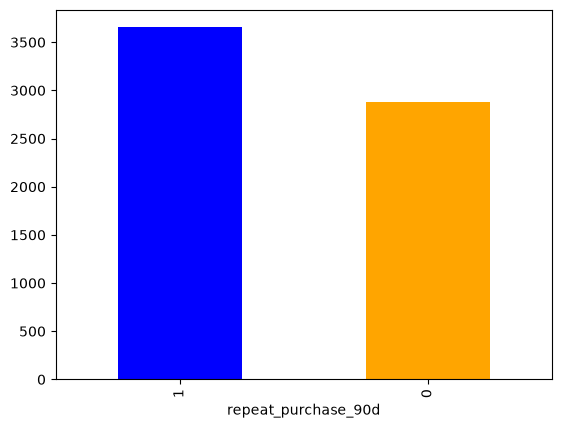

In [36]:
y_train = train['repeat_purchase_90d']
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

# create a bar chart to visualize the distribution of the repeat_purchase_90d variable
ax = y_train.value_counts().plot(kind='bar', color=['blue', 'orange'])

<a class="anchor" id="8th-bullet">
    
### 1.5. Missing values, duplicates and identifiers
   
</a>

In [37]:
# check columns with missing values (train)
missing_train = train.isnull().sum()
missing_train

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

In [38]:
# check columns with missing values (test)
missing_test = test.isnull().sum()
missing_test

Total a Pagar                      0
Total Bruto                        0
Total Liquido                      0
Total Imp_                         0
Total Portes                       0
Total Desc_ Global                 0
Total Desc_ Linha                  0
Custo                              0
N_ Detalhes                        0
invoice_count_current_purchase     0
days_since_previous_purchase      52
customer_tenure_days               0
prior_purchase_count               0
prior_total_spend                  0
prior_mean_purchase_value         52
prior_std_purchase_value          46
prior_min_purchase_value          22
prior_max_purchase_value          22
prior_mean_gap_days               76
prior_std_gap_days                69
purchase_count_30d                 0
spend_30d                          0
purchase_count_90d                 0
spend_90d                          0
purchase_count_180d                0
spend_180d                         0
purchase_count_365d                0
s

In [39]:
# rows where almost every feature is missing (train)

# select feature columns except IDs and repeat_purchase_90d
feature_columns = train.columns.drop(['customer_id', 'ID', 'repeat_purchase_90d'])

# identify rows where all feature values are missing
empty_rows_train = train[feature_columns].isna().all(axis=1)
print("Rows with every feature missing:", empty_rows_train.sum())
print("Target in those rows:", train.loc[empty_rows_train, 'repeat_purchase_90d'].value_counts().to_dict())

Rows with every feature missing: 65
Target in those rows: {1: 33, 0: 32}


In [40]:
# Previous purchase features are missing for a customer's first purchase

first_purchase = train['prior_purchase_count'] == 0
print('First purchases:', first_purchase.sum())

First purchases: 603


In [41]:
# check duplicated rows and IDs
print('Duplicated training rows:', train.duplicated().sum())
print('Duplicated training IDs:', train['ID'].duplicated().sum())
print("Duplicated rows ignoring ID:", train.drop(columns="ID").duplicated().sum())

# costumers
print('Unique customers in train:', train['customer_id'].nunique())
print('Unique customers in test:', test['customer_id'].nunique())

Duplicated training rows: 0
Duplicated training IDs: 0
Duplicated rows ignoring ID: 10
Unique customers in train: 610
Unique customers in test: 206


- **65 training rows are empty** (only `ID`, `costumer_id` and `repeat_purchase_90d` are filled) and the `repeat_purchase_90d` is split 33/32 in them: they carry no information and are removed.

<a class="anchor" id="8th-bullet">
    
### 1.6. Consistency of categorical variables
   
</a>

In [58]:
# remove accents, extra spaces and convert to lowercase all string columns
import unicodedata


def normalize_string_columns(df: pd.DataFrame) -> pd.DataFrame:
    df_clean = df.copy()
    df_clean.columns = df_clean.columns.str.strip().str.lower()
    text_columns = df_clean.select_dtypes(include=['object', 'string']).columns
    
    for col in text_columns:
        df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()
        df_clean[col] = df_clean[col].apply(
            lambda x: ''.join(c for c in unicodedata.normalize('NFD', x) 
                              if unicodedata.category(c) != 'Mn') if pd.notna(x) else x
        )
        df_clean[col] = df_clean[col].replace('nan', pd.NA)
        
    return df_clean

CATEGORICAL = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse", "document_series"]
train_normalized = normalize_string_columns(train)
pd.DataFrame({
    "levels_original": train[CATEGORICAL].nunique(),
    "levels_normalized": train_normalized[CATEGORICAL].nunique(),
    "levels_only_in_test": [(~test[c].dropna().isin(train[c].dropna())).sum() for c in CATEGORICAL],
})

,levels_original,levels_normalized,levels_only_in_test
payment_type,9,9,3
salesperson,9,9,0
commercial_zone,5,5,209
transport_method,80,80,63
warehouse,2,2,7
document_series,3,3,0


<a class="anchor" id="8th-bullet">
    
### 1.7. Train vs Test
   
</a>

Train period: 2015-07-11 to 2025-02-15
Test period: 2025-05-24 to 2026-10-06


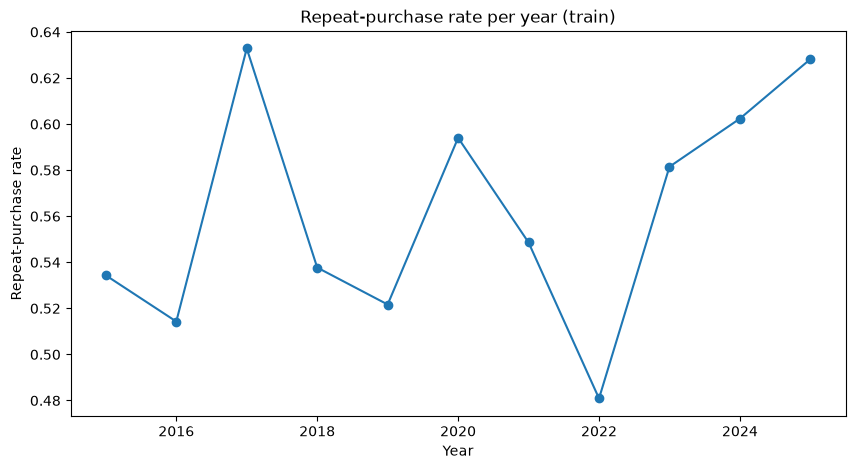

,train_median,test_median
customer_tenure_days,918.00,2662.00
prior_purchase_count,11.00,28.00
prior_total_spend,6754.31,25186.53
purchase_count_365d,3.00,4.00
days_since_previous_purchase,57.00,59.00


In [43]:
train_dates = pd.to_datetime(train['purchase_date'])
test_dates = pd.to_datetime(test['purchase_date'])

print("Train period:", train_dates.min().date(), "to", train_dates.max().date())
print("Test period:", test_dates.min().date(), "to", test_dates.max().date())

yearly = train.groupby(train_dates.dt.year)['repeat_purchase_90d'].agg(['mean', 'size'])
ax = yearly['mean'].plot(marker='o', figsize=(10, 5))
ax.set(title = 'Repeat-purchase rate per year (train)', xlabel = 'Year', ylabel = 'Repeat-purchase rate')
plt.show()

pd.DataFrame({"train_median": train.median(numeric_only=True),
              "test_median": test.median(numeric_only=True)}).loc[
    ["customer_tenure_days", "prior_purchase_count", "prior_total_spend", "purchase_count_365d", "days_since_previous_purchase"]]

Training purchases go from July 2015 to February 2025 and test purchases from May 2025 to October 2025. Therefore:
- Model assessment must **respect time oreder** (train on the past, validate on the future), otherwise the validation score would be optimistic.
- Test costumers have about **2.5x more tenure and prior purchases** than training costumers simply beacause time has passed.

<a class="anchor" id="8th-bullet">
    
### 1.8. Univariate and bivariate relationships with `repeat_purchase_90d`
   
</a>

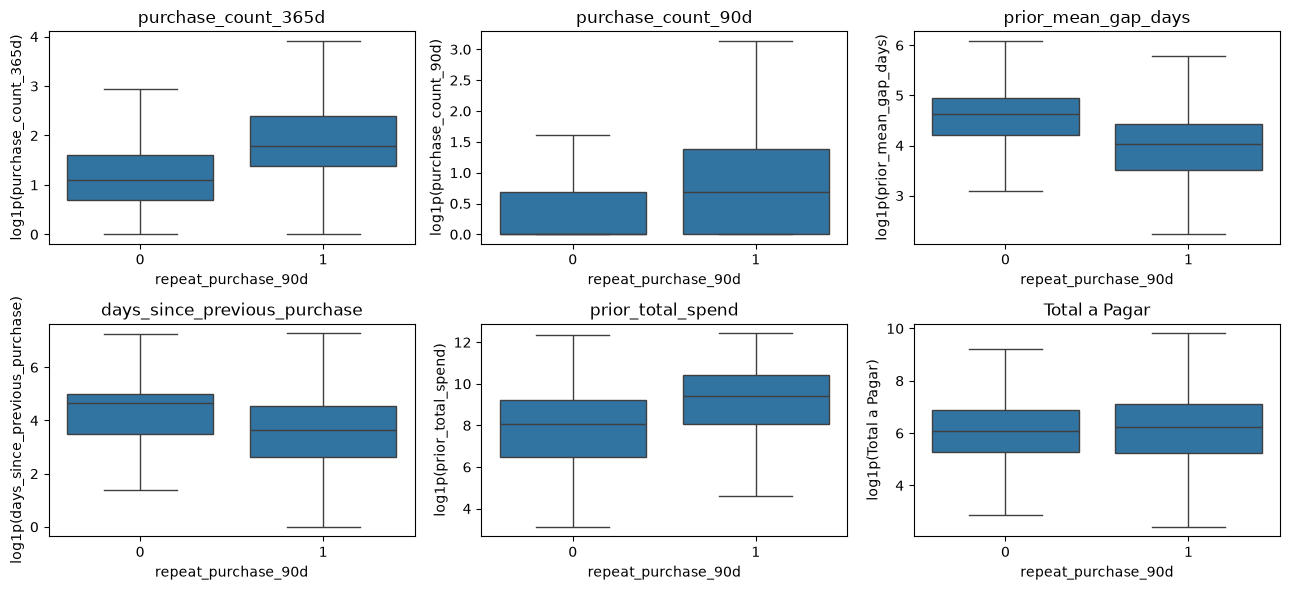

In [44]:
key_numeric = ["purchase_count_365d", "purchase_count_90d", "prior_mean_gap_days",
               "days_since_previous_purchase", "prior_total_spend", "Total a Pagar"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), key_numeric):
    sns.boxplot(data=train, x='repeat_purchase_90d', y=np.log1p(train[col].clip(lower=0, upper=1e7)), ax=ax, showfliers=False)
    ax.set(title=col, ylabel=f"log1p({col})")
plt.tight_layout()
plt.show()

- Costumers who **buy often** and have **short historical gaps** are much more likely to buy again within 90 days (frequency behaviour is the main signal).
- The value of the current purchase (`Total a Pagar`) hardly separates the classes.

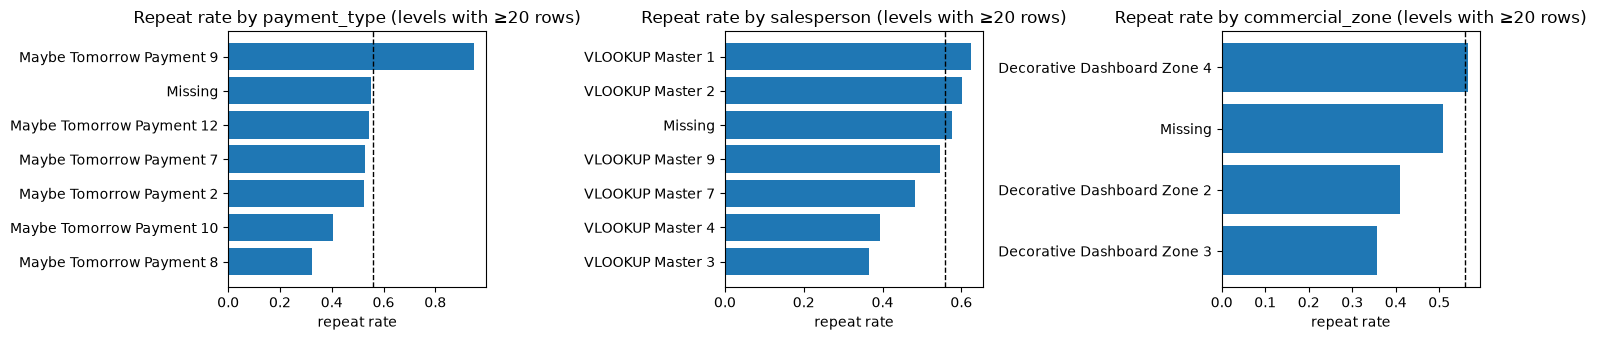

In [45]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["payment_type", "salesperson", "commercial_zone"]):
    rate = train.groupby(train[col].fillna("Missing"))['repeat_purchase_90d'].agg(["mean", "size"])
    rate = rate[rate["size"] >= 20].sort_values("mean")
    ax.barh(rate.index, rate["mean"])
    ax.axvline(y_train.mean(), color="black", ls="--", lw=1)
    ax.set(title=f"Repeat rate by {col} (levels with ≥20 rows)", xlabel="repeat rate")
plt.tight_layout()
plt.show()

- `payment_type` *Maybe Tomorrow Payment 9* has a ≈95% repeat rate (502 rows) and `salesperson` *VLOOKUP Master 2* only ≈39% (these categoricals carry real information).

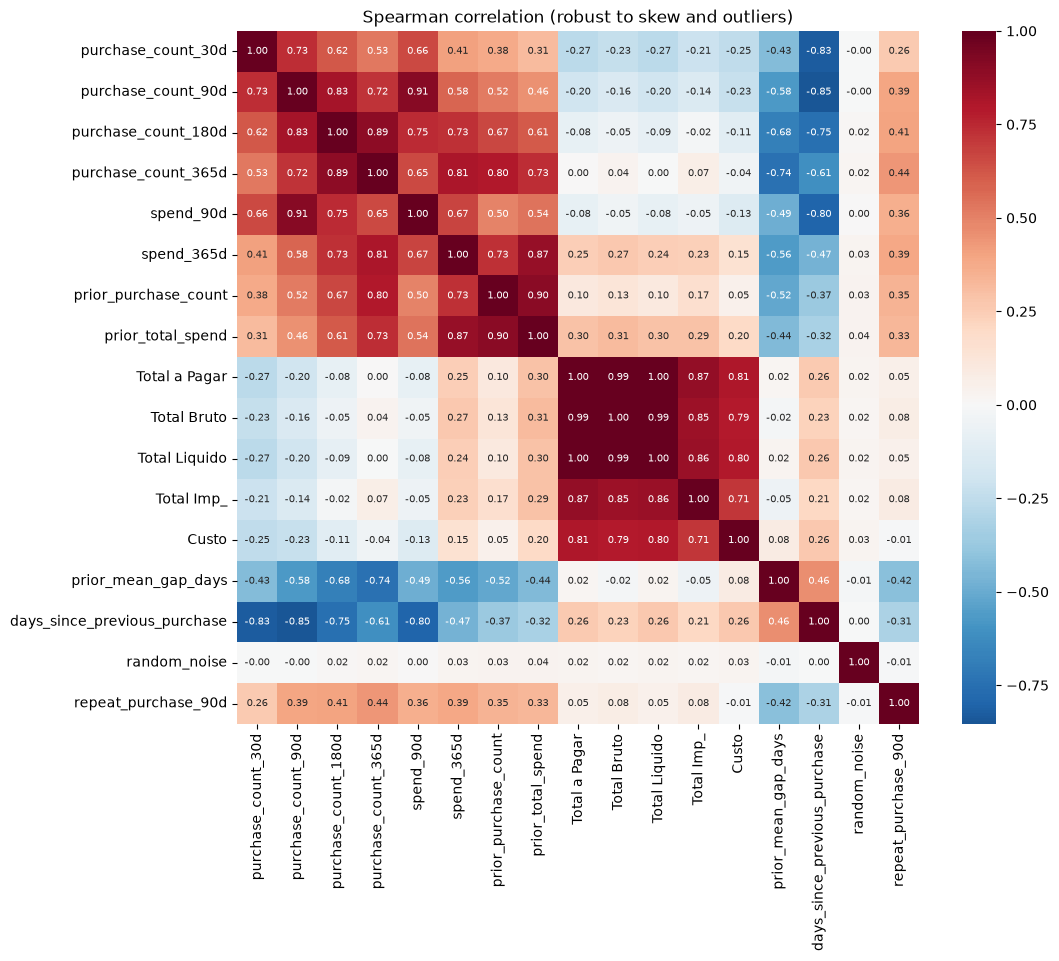

In [46]:
corr_cols = ["purchase_count_30d", "purchase_count_90d", "purchase_count_180d", "purchase_count_365d",
             "spend_90d", "spend_365d", "prior_purchase_count", "prior_total_spend",
             "Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Custo",
             "prior_mean_gap_days", "days_since_previous_purchase", "random_noise", "repeat_purchase_90d"]
plt.figure(figsize=(11, 9))
sns.heatmap(train[corr_cols].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Spearman correlation (robust to skew and outliers)")
plt.show()

- Strong **redundancy**: `Total a Pagar`, `Total Bruto`, `Total Líquido`, `Total Imp_` and `Custo` are almost perfectly correlated (they are the same amount before/after tax and discounts), and each rolling count is highly correlated with its rolling spend. Feature selection must remove this redundancy.
- `random_noise` has ≈0 correlation with the target and every other variable.

<a class="anchor" id="8th-bullet">
    
### 1.9. The auxiliary `clientes.csv` table
   
</a>

In [47]:
print("Duplicated customer_id in clientes:", clientes["customer_id"].duplicated().sum())
print(clientes.nunique().to_string())

Duplicated customer_id in clientes: 0
customer_id            1143
country_or_region        11
commercial_region        37
island                   10
municipality            183
city                    417
postal_area             271
postal_code             828
street                  511
address                1120
customer_type             0
company_name           1141
customer_since_year      12


- One row per costumer, every train/test costumer is present.
- `costumer_type` is 100% missing and `adress`, `street`, `postal_code`, `city`, `company_name` have hundreds of levels (pratically one per costumer, so they behave as identifiers).

<a class="anchor" id="7th-bullet">

## 2. Cleaning and pre-processing

</a>

The work is split in two parts so that **no information from `test.csv` is used to fit any transforamtion**: <br>
1.  `clean_data` - row-by-row rules taht do not learn anything from the data (fixing impossible values, deterministic new features).
2. A scikit-learn `Pipeline` - imputation, log transform, scaling and one-hot encoding. Iis statistics (medians, means, categories) are learns with `fit` on training data only, and re-learned inside every cross-validation fold.

<a class="anchor" id="8th-bullet">
    
### 2.1. Rule-based data cleaning
   
</a>

| Problem | Decision | Reason |
|---|---|---|
| 65 empty rows | drop (train only) | no information; target ≈50/50 |
| `prior_mean_purchase_value` = 1e9 or < 0; `spend_365d` = 1e9 or < 0 | set to NaN | impossible values (sentinel codes) |
| `days_since_previous_purchase`, `prior_mean_gap_days` < 0 | set to NaN | a gap cannot be negative |
| `prior_mean_purchase_value` missing/corrupted but `prior_purchase_count > 0` | recompute as `prior_total_spend / prior_purchase_count` | the identity holds in 99% of valid rows, so the value can be rebuilt exactly instead of imputed |

New features (all computed from the same row, so no leakage):
- `is_first_purchase` — makes the structural missingness explicit.
- `purchases_per_year` — purchase rate; more stable over time than raw cumulative counts (see drift in 2.5).
- `recency_vs_usual_gap` — current gap divided by the customer's usual gap (is the customer "late"?).
- `share_recent_purchases` — share of last-year purchases that happened in the last 90 days (accelerating vs slowing customer).
- `margin_rate`, `discount_rate`, `value_vs_mean` — relative versions of the monetary values (scale-free).
- `purchase_month` — possible seasonality.

In [51]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    # Fix impossible values and add row-level features; learns nothing from the data.
    df = df.copy()

    # impossible values -> missing
    for col in ["prior_mean_purchase_value", "spend_365d"]:
        df.loc[(df[col] < 0) | (df[col] >= 1e8), col] = np.nan
    for col in ["days_since_previous_purchase", "prior_mean_gap_days"]:
        df.loc[df[col] < 0, col] = np.nan

    # rebuild the prior mean from its definition when possible
    rebuild = df["prior_mean_purchase_value"].isna() & (df["prior_purchase_count"] > 0)
    df.loc[rebuild, "prior_mean_purchase_value"] = df["prior_total_spend"] / df["prior_purchase_count"]

    # new features
    df["purchase_month"] = pd.to_datetime(df["purchase_date"]).dt.month
    df["is_first_purchase"] = (df["prior_purchase_count"] == 0).astype(int)
    df["purchases_per_year"] = df["prior_purchase_count"] / (df["customer_tenure_days"].clip(lower=1) / 365)
    df["recency_vs_usual_gap"] = df["days_since_previous_purchase"] / df["prior_mean_gap_days"].replace(0, np.nan)
    df["share_recent_purchases"] = df["purchase_count_90d"] / df["purchase_count_365d"].replace(0, np.nan)
    df["margin_rate"] = (df["Total Liquido"] - df["Custo"]) / df["Total Liquido"]
    df["discount_rate"] = df["Total Desc_ Linha"] / df["Total Bruto"]
    df["value_vs_mean"] = df["Total a Pagar"] / df["prior_mean_purchase_value"]
    return df


train_clean = clean_data(train.loc[~empty_rows_train])
test_clean = clean_data(test)

# join the candidate customer attributes (left join keeps every purchase row)
CLIENT_COLS = ["country_or_region", "commercial_region", "customer_since_year"]
train_clean = train_clean.merge(clientes[["customer_id"] + CLIENT_COLS], on="customer_id", how="left")
test_clean = test_clean.merge(clientes[["customer_id"] + CLIENT_COLS], on="customer_id", how="left")

# sort chronologically: required by the time-aware validation
train_clean = train_clean.sort_values("purchase_date", kind="stable").reset_index(drop=True)

print("train:", train.shape, "to", train_clean.shape, "| test:", test.shape, "to", test_clean.shape)
print("Remaining impossible values:",
      int((train_clean[["prior_mean_purchase_value", "spend_365d"]] >= 1e8).sum().sum()),
      int((train_clean[["days_since_previous_purchase", "prior_mean_gap_days"]] < 0).sum().sum()))

train: (6534, 39) to (6469, 50) | test: (986, 38) to (986, 49)
Remaining impossible values: 0 0


<a class="anchor" id="8th-bullet">
    
### 2.2. Development set and temporal hold-out
   
</a>

The cleaned training data is split by time: the oldest 80% is the *development set* (exploring feature selection, cross-validation, tuning) and the most recent 20% is a *hold-out* that is only used once, at the end, to estimate the performance of the final model on "future" data.

In [52]:
split_point = int(len(train_clean) * 0.8)
dev = train_clean.iloc[:split_point]
holdout = train_clean.iloc[split_point:]
print('Development:', dev.shape, dev['purchase_date'].min(), 'to', dev['purchase_date'].max())
print('Holdout:', holdout.shape, holdout['purchase_date'].min(), 'to', holdout['purchase_date'].max())

Development: (5175, 50) 2015-07-11 to 2023-06-17
Holdout: (1294, 50) 2023-06-17 to 2025-02-15


<a class="anchor" id="8th-bullet">
    
### 2.3. Pre-processing pipeline
   
</a>

- **Numeric**: median imputation + missing-value indicator.
- **Categorical**: missing values become their own level `Missing`, then one-hot encoding. Levels with fewer than 20 training rows are grouped into an "infrequent" level, and levels never seen in training are mapped to it instead of breaking the model.

In [53]:
RATE_FEATURES = {"purchase_month", "is_first_purchase", "recency_vs_usual_gap", "share_recent_purchases",
                 "margin_rate", "discount_rate", "value_vs_mean", "customer_since_year"}


def signed_log1p(X):
    return np.sign(X) * np.log1p(np.abs(X))


def make_preprocessor(numeric, categorical):
    # Build the ColumnTransformer for a given list of numeric and categorical columns.
    skewed = [c for c in numeric if c not in RATE_FEATURES]
    plain = [c for c in numeric if c in RATE_FEATURES]
    num_log = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                        ("scale", StandardScaler())])
    num_plain = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                             sparse_output=False))])
    return ColumnTransformer([("num_log", num_log, skewed),
                              ("num_plain", num_plain, plain),
                              ("cat", cat, categorical)])


def make_model(estimator, numeric, categorical):
    return Pipeline([("prep", make_preprocessor(numeric, categorical)), ("model", estimator)])

<a class="anchor" id="7th-bullet">

## 3. Feature selection

</a>

Strategy:
1. **Critical removal of identifier-like/non-informative variables**.
2. **Filter methods** - numeric: near-constant variables, weak relevance to the target, redundancy; categorical: χ² test of independence.
3. **Validation** - compare the filtered set with all features and with a wrapper method using time-series cross-validation, and keep the smallest set that does not lose performance.

<a class="anchor" id="8th-bullet">
    
### 3.1. Idendifier-like variables and `random_noise`
   
</a>

In [55]:
for col in ["ID", "customer_id", "random_noise"]:
    rho = dev[[col, "repeat_purchase_90d"]].corr(method="spearman").iloc[0, 1]
    print(f"{col:13s} Spearman rho with target = {rho:+.3f} | distinct values = {dev[col].nunique()}")

ID            Spearman rho with target = +0.021 | distinct values = 5175
customer_id   Spearman rho with target = -0.137 | distinct values = 561
random_noise  Spearman rho with target = -0.013 | distinct values = 5175


- `ID` is a unique row label (no relation with `repeat_purchase_90d` or with time): **dropped**; is is kept aside only to build the submission.
- `costumer_id` is an anonymised label. Its numeric value has no meaning. Its correlation of ≈-0.14 is an artefact: a few very frequent customers contribute many rows, so whatever IDs they happen to have get associated with "repeat". This would not generalise to new customers, and using it as a category would just memorise individual customers. **Dropped** — the customer's behaviour is already described by the historical features.
- `random_noise` has ρ≈0 with the target. **Dropped**.
- `purchase_date` is not used directly: the test set is in a later period, so a model would extrapolate in time. Its seasonal part is kept through `purchase_month`.

<a class="anchor" id="8th-bullet">
    
### 3.2. Filter methods - numeric features
   
</a>

In [62]:
NOT_FEATURES = ["ID", "customer_id", "random_noise", "purchase_date", "repeat_purchase_90d"] + CATEGORICAL + CLIENT_COLS
numeric_candidates = [c for c in dev.columns if c not in NOT_FEATURES]

# (a) near-constant: one value in more than 95% of the rows
top_share = dev[numeric_candidates].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_constant = top_share[top_share > 0.95].index.tolist()

# (b) relevance: |Spearman rho| with the target
relevance = dev[numeric_candidates].corrwith(dev["repeat_purchase_90d"], method="spearman").abs().sort_values(ascending=False)
weak = relevance[relevance < 0.03].index.tolist()

# (c) redundancy: walk from most to least relevant, skip a feature if |rho| > 0.85 with one already kept
pairwise = dev[numeric_candidates].corr(method="spearman").abs()
numeric_selected, redundant = [], {}
for col in relevance.index:
    if col in near_constant or col in weak:
        continue
    twin = next((k for k in numeric_selected if pairwise.loc[col, k] > 0.85), None)
    if twin is None:
        numeric_selected.append(col)
    else:
        redundant[col] = twin

print("Near-constant:", near_constant)
print("Weak relevance:", weak)
print("Redundant (feature -> kept twin):")
for col, twin in redundant.items():
    print(f"   {col:32s} -> {twin}")
print(f"\nNumeric features kept: {len(numeric_selected)} of {len(numeric_candidates)}")

Near-constant: ['Total Desc_ Global']
Weak relevance: ['Custo', 'Total Portes', 'purchase_month']
Redundant (feature -> kept twin):
   purchases_per_year               -> prior_mean_gap_days
   purchase_count_180d              -> purchase_count_365d
   spend_180d                       -> spend_365d
   spend_90d                        -> purchase_count_90d
   prior_total_spend                -> spend_365d
   days_since_previous_purchase     -> purchase_count_90d
   spend_30d                        -> purchase_count_30d
   Total Desc_ Linha                -> discount_rate
   prior_std_purchase_value         -> prior_max_purchase_value
   Total Bruto                      -> Total Imp_
   Total a Pagar                    -> Total Imp_
   Total Liquido                    -> Total Imp_

Numeric features kept: 20 of 36


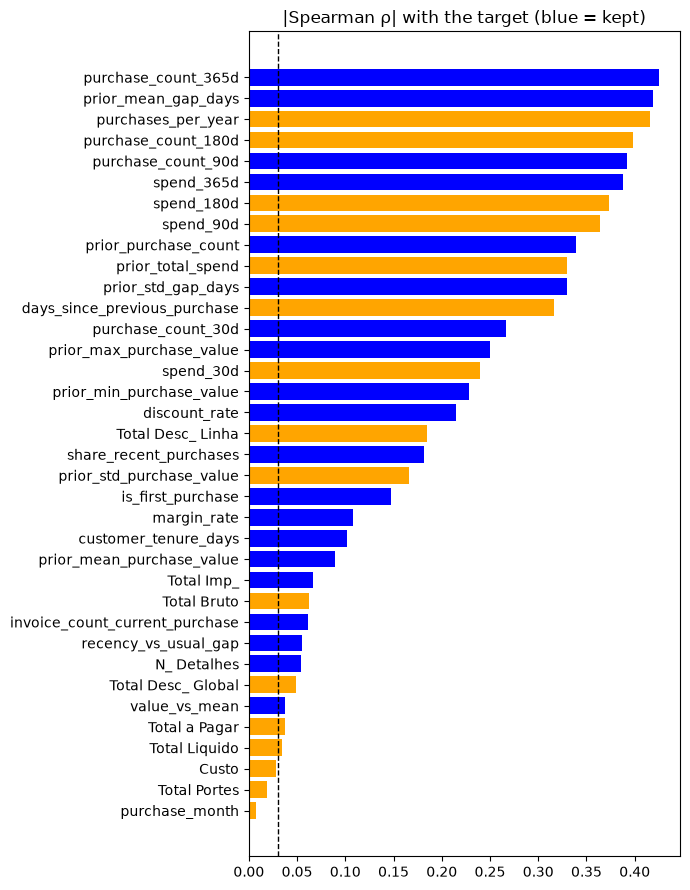

In [63]:
colors = ["Blue" if c in numeric_selected else "Orange" for c in relevance.index]
plt.figure(figsize=(7, 9))
plt.barh(relevance.index[::-1], relevance.values[::-1], color=colors[::-1])
plt.axvline(0.03, color="black", ls="--", lw=1)
plt.title("|Spearman ρ| with the target (blue = kept)")
plt.tight_layout()
plt.show()

<a class="anchor" id="8th-bullet">
    
### 3.3. Filter methods - categorical features (χ² test)
   
</a>

In [65]:
rows = []
for col in CATEGORICAL + ["country_or_region", "commercial_region"]:
    table = pd.crosstab(dev[col].fillna("Missing"), dev["repeat_purchase_90d"])
    chi2, p, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"feature": col, "levels": table.shape[0], "chi2": chi2, "p_value": p, "cramers_v": cramers_v})
pd.DataFrame(rows).sort_values("cramers_v", ascending=False).round(4)

,feature,levels,chi2,p_value,cramers_v
3,transport_method,76,483.4904,0.0000,0.3057
7,commercial_region,32,388.9935,0.0000,0.2742
0,payment_type,9,324.1293,0.0000,0.2503
1,salesperson,10,207.0352,0.0000,0.2000
6,country_or_region,7,23.3940,0.0007,0.0672
2,commercial_zone,5,21.3920,0.0003,0.0643
4,warehouse,3,9.4573,0.0088,0.0427
5,document_series,3,8.0165,0.0182,0.0394


- `payment_type`, `salesperson`, `commercial_zone` and `warehouse` are associated with `repeat_purchase_90d` and have a few levels -> **kept**
- `document_series` has the weakest association of all (Cramér's V ≈ 0.04; with >5,000 rows even a negligible effect becomes "significant") → **candidate for removal**.
- `transport_method` shows the largest χ², but with 76 levels many cells are tiny (the χ² is inflated) and 63 test rows use levels that do not exist in training → **candidate for removal**.
- `country_or_region` / `commercial_region` (from `clientes.csv`) are associated with the target; whether they add information *beyond* the purchase history.

In [66]:
categorical_selected = ["payment_type", "salesperson", "commercial_zone", "warehouse"]